# 02 - EDA: images

Image-level EDA now that `data/raw/images/` is populated: file coverage, sizes/aspect ratios, and whether image width tracks transcription length (sanity check that these are single-line crops).

In [1]:
import sys
sys.path.append('..')

import pandas as pd
from PIL import Image

from src.config import IMAGES_DIR
from src.data import build_image_path, load_raw_data

train = load_raw_data('train')
test = load_raw_data('test')
all_ids = pd.concat([train['ID'], test['ID']], ignore_index=True)
len(all_ids)

5472

In [2]:
# Coverage - every train/test ID should have a matching image file
missing = [rid for rid in all_ids if not build_image_path(rid).exists()]
extra = set(p.stem for p in IMAGES_DIR.glob('*.jpg')) - set(all_ids)
len(missing), len(extra)

(0, 0)

In [3]:
# Size / mode per image (PIL.Image.open is lazy - only reads the header here)
records = []
for rid in all_ids:
    with Image.open(build_image_path(rid)) as im:
        w, h = im.size
        records.append({'ID': rid, 'width': w, 'height': h, 'mode': im.mode, 'format': im.format})

sizes = pd.DataFrame(records)
sizes['aspect_ratio'] = sizes['width'] / sizes['height']
sizes.shape

(5472, 6)

In [4]:
sizes[['width', 'height', 'aspect_ratio']].describe()

,width,height,aspect_ratio
count,5472.000000,5472.000000,5472.000000
mean,1914.286367,136.069993,17.107340
std,1471.438780,132.755822,4.962653
min,267.000000,28.000000,3.034091
25%,1065.000000,51.000000,13.005224
50%,1119.000000,65.000000,16.784144
75%,2815.500000,214.250000,21.133370
max,6051.000000,1131.000000,40.535714


In [5]:
sizes['mode'].value_counts(), sizes['format'].value_counts()

(mode
 RGB    5472
 Name: count, dtype: int64,
 format
 JPEG    5472
 Name: count, dtype: int64)

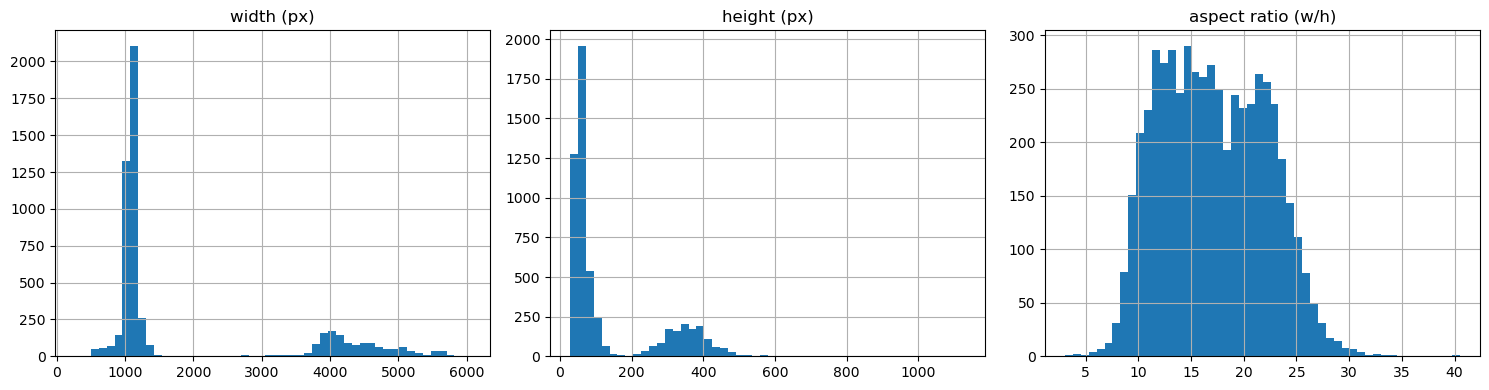

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sizes['width'].hist(bins=50, ax=axes[0]); axes[0].set_title('width (px)')
sizes['height'].hist(bins=50, ax=axes[1]); axes[1].set_title('height (px)')
sizes['aspect_ratio'].hist(bins=50, ax=axes[2]); axes[2].set_title('aspect ratio (w/h)')
fig.tight_layout()

In [7]:
# Sanity check: these should be single-line crops, so width should scale with
# transcription length far more than height does (height ~ line height, roughly constant).
merged = sizes.merge(train[['ID', 'Target']], on='ID')
merged['target_len'] = merged['Target'].str.len()
merged[['width', 'height', 'target_len']].corr()

,width,height,target_len
width,1.000000,0.949029,-0.124681
height,0.949029,1.000000,-0.226522
target_len,-0.124681,-0.226522,1.000000


In [8]:
# Outliers - unusually small/large images worth a manual look
sizes.sort_values('width').head(5), sizes.sort_values('width').tail(5)

(                    ID  width  height mode format  aspect_ratio
 2280  PO7QQLWIFOT65BTz    267      88  RGB   JPEG      3.034091
 3570  3ZxOeKcOr5wUYyk0    392      70  RGB   JPEG      5.600000
 3092  EcxuqKeZl7OQexfB    461     117  RGB   JPEG      3.940171
 2864  JL1oKf5gzR0VtxCP    482      72  RGB   JPEG      6.694444
 25    zF6Y0Q8CW0z7x0EU    497      55  RGB   JPEG      9.036364,
                     ID  width  height mode format  aspect_ratio
 226   XRRpqOq44BAzgcwg   5945     278  RGB   JPEG     21.384892
 513   e75E38DWZci4jQnJ   5978     474  RGB   JPEG     12.611814
 4679  Ox1UmDPioFzAcres   5998     309  RGB   JPEG     19.411003
 460   XEhx6eusUFtBNhhD   6030     413  RGB   JPEG     14.600484
 4492  lpRvSSp87iW3FEOP   6051     299  RGB   JPEG     20.237458)

In [9]:
sizes.sort_values('height').head(5), sizes.sort_values('height').tail(5)

(                    ID  width  height mode format  aspect_ratio
 5281  267xSV848jfudVh1   1135      28  RGB   JPEG     40.535714
 5012  KgRK3LcGjeQnmuz9    892      30  RGB   JPEG     29.733333
 741   6SVyPySNfbd5W412   1069      31  RGB   JPEG     34.483871
 4335  AQLKHu7qnQTupqzi    986      32  RGB   JPEG     30.812500
 3327  z9B6NB4pQnZ1ITZK    596      33  RGB   JPEG     18.060606,
                     ID  width  height mode format  aspect_ratio
 2973  3JyPMRah7BH53ejW   4391     589  RGB   JPEG      7.455008
 4674  gSRiLOj8cDjjmcYn   2699     600  RGB   JPEG      4.498333
 4664  TlAiuect11Kry8hF   5207     617  RGB   JPEG      8.439222
 219   R6iYPb7MHFiHtXH6   3968     625  RGB   JPEG      6.348800
 1880  gP7kGWfDFYMbZ8nO   5929    1131  RGB   JPEG      5.242263)

## Manual look at the width/height extremes

The outlier tables above (cells 8/9) only printed numbers. Rendering the actual images to check two things: (1) are the smallest crops still legible, not corrupted/mis-cropped, and (2) are the largest crops still genuinely single lines, or do the biggest ones actually contain multiple lines (which would break the single-line-crop assumption this project's OCR approaches rely on).

In [10]:
import matplotlib.pyplot as plt
from PIL import Image


def show_images(ids_df, label):
    for _, row in ids_df.iterrows():
        img = Image.open(build_image_path(row['ID']))
        fig_w = max(min(img.width / 120, 14), 3)
        fig_h = max(img.height / 120, 1)
        fig, ax = plt.subplots(figsize=(fig_w, fig_h))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"{label} | {row['ID']} | {row['width']}x{row['height']}px")
        plt.show()

### Smallest width (3)

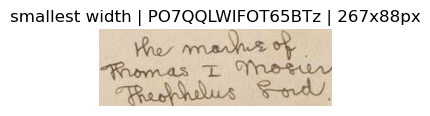

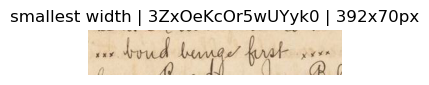

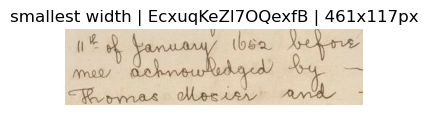

In [11]:
show_images(sizes.sort_values('width').head(3), 'smallest width')

**Observation (manual read):** these aren't simply short single lines. `PO7QQLWIFOT65BTz` and `EcxuqKeZl7OQexfB` are cramped, stacked multi-line snippets (witness "mark"/signature blocks, e.g. "the marks of Thomas I Mosier..." across 2-3 short lines) — the single-line-crop assumption does not hold for every row. `3ZxOeKcOr5wUYyk0` also shows a sliver of the line above bleeding into the top edge of the crop.

### Largest width (3)

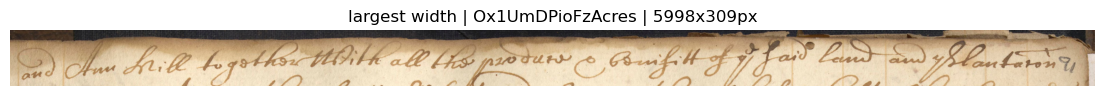

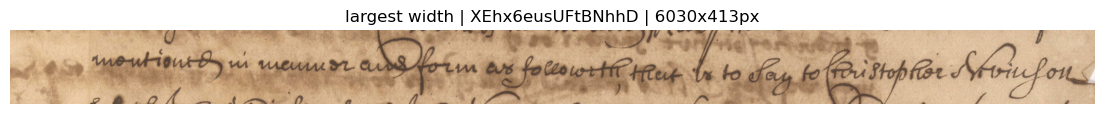

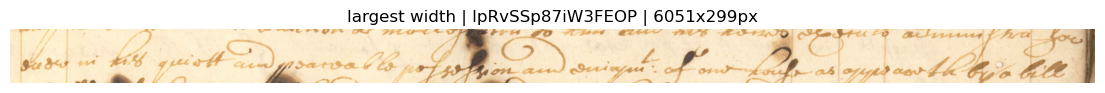

In [12]:
show_images(sizes.sort_values('width').tail(3), 'largest width')

**Observation:** these are legitimate long single lines spanning close to the full page width — width scales with real content plus, for `e75E38DWZci4jQnJ`, large decorative capital-letter flourishes that also add extra height without adding another line.

### Smallest height (3)

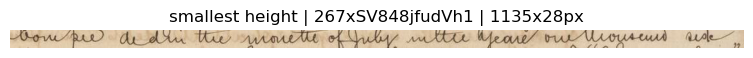

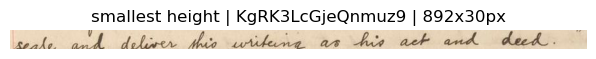

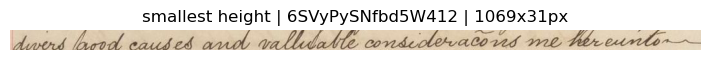

In [13]:
show_images(sizes.sort_values('height').head(3), 'smallest height')

**Observation:** clean, legitimate single lines — just tightly cropped vertically with little margin above/below the text. No quality issue here.

### Largest height (3)

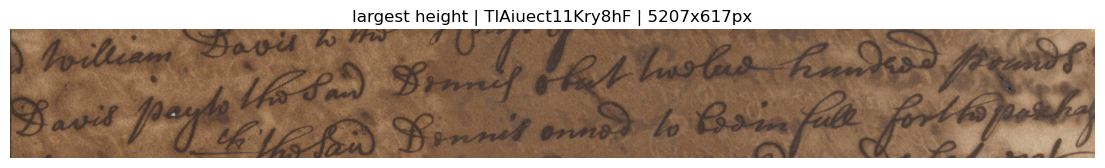

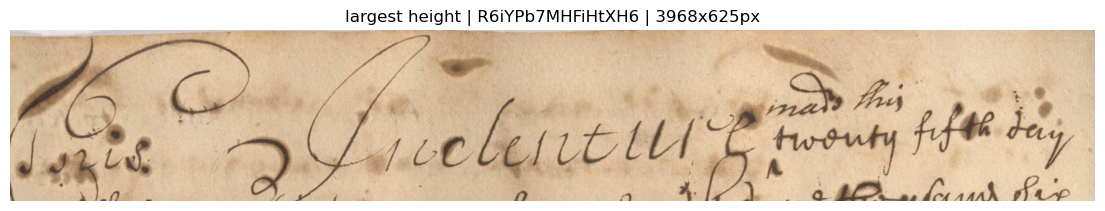

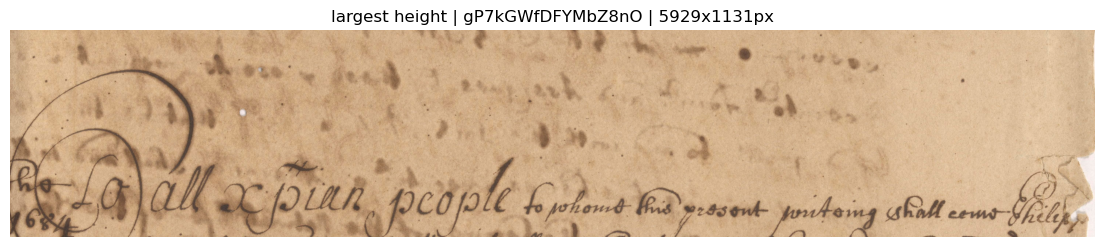

In [14]:
show_images(sizes.sort_values('height').tail(3), 'largest height')

**Observation:** mixed causes, not just "more text": `3JyPMRah7BH53ejW` shows bleed-through from the line above (extra ink not part of the transcription); `gP7kGWfDFYMbZ8nO` (tallest image in the whole dataset, 1131px) shows heavy staining and what looks like a second line/large signature flourish; `gSRiLOj8cDjjmcYn` looks like a completely different content type — text along a drawn diagonal boundary line ("Land Staked out for Mr. John Gardner..."), i.e. a land-survey/plat annotation rather than a prose legal-deed line. Confirms the earlier finding that extreme height comes from scan/crop artifacts, not from longer transcriptions.

## Summary of the manual outlier review

- A handful of crops are cramped multi-line signature/mark blocks, not single running-prose lines — the single-line assumption is mostly, but not universally, true.
- Several outliers show bleed-through from the adjacent line at the crop edge (extra ink not reflected in the `Target` transcription).
- At least one outlier is a land-survey/plat annotation rather than deed prose — a distinct sub-population worth keeping in mind if preprocessing assumes uniform document layout.
- None of this is a data error to fix — it's real variation in the source scans. Worth remembering during model error analysis so these known-hard cases (multi-line crops, bleed-through, non-prose content) aren't mistaken for generic model failures.